In [ ]:
import numpy as np
import cupy as cp
import gc
from scipy.linalg import eigh 
from scipy.special import comb 

from itertools import combinations    

import networkx as nx

import matplotlib.pyplot as plt
import seaborn as sns 

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "text.usetex": False, 
    "font.family": "serif",
    "axes.labelsize": 12,
    "font.size": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

%load_ext autoreload
%autoreload 2

import mylib as ml

In [2]:
N = 16
Gamma_tensor = ml.Dirac_gen_GPU(N)

tetrahedra = np.array(list(combinations(range(N), 4)), dtype = np.int32)
triangles = np.array(list(combinations(range(N), 3)), dtype = np.int32)
links = np.array(list(combinations(range(N), 2)), dtype = np.int32)

_, _, matrices_4 = ml.build_matrices_GPU(Gamma_tensor, links, triangles, tetrahedra)

    
cp.get_default_memory_pool().free_all_blocks()
cp.get_default_pinned_memory_pool().free_all_blocks()

gc.collect()

Gamma_5 = Gamma_tensor[0]
for i in range(N-1):
    Gamma_5 = Gamma_5@Gamma_tensor[i+1]

diag = cp.diag(Gamma_5)

if cp.allclose(diag.real, 0):
    mask = (diag.imag > 0)
else:
    mask = (diag.real >0)

matrices_4 = matrices_4[:, mask, :][:,:,mask]

In [ ]:
hamil_matrices = matrices_4.get()

p = [0.01,0.011,0.012,0.016, 0.02, 0.1] # Erdős-Rényi probabilities

J_0 = 1.0
J = []
J = J_0/np.sqrt(p) 

M=int(comb(N,4))
sigma = np.sqrt(6) * J_0/(N**(1.5))

dim = hamil_matrices.shape[1]

hamil = np.zeros((dim, dim))


r_list = []
r_index_list = [] 


N_iter = 500

r_mean = np.zeros((len(p),N_iter)) 
r_index_mean = np.zeros((len(p),N_iter)) 

for k in range(len(p)):
  spacing = []
  r = []
  r_index = [] 
  valid_net = 0

  while valid_net < N_iter:
    couplings = np.random.normal(loc=0.0, scale=sigma, size=M)

    mask = np.random.rand(M) < p[k]
    couplings = couplings * mask

    G = nx.Graph()
    G.add_nodes_from(range(N))

    for idx, (j, l, m, n) in enumerate(combinations(range(N),4)):
      if couplings[idx] != 0:
        G.add_edge(j, l)
        G.add_edge(j, n)
        G.add_edge(j, m)
        G.add_edge(l, m)
        G.add_edge(l, n)
        G.add_edge(m, n)

    if not nx.is_connected(G):
      continue    
        

    hamil = np.tensordot(couplings, hamil_matrices, axes=([0], [0]))

    energies = np.linalg.eigh(hamil)[0]

    lenght = len(energies)
    trim = int(lenght*0.1)
    bulk_energies = energies[trim : -trim]

    new_spacing = np.diff(bulk_energies)

    new_spacing = new_spacing[new_spacing > 1e-10]

    if len(new_spacing) < 2:
     continue
  

    spacing.extend(new_spacing)

    new_r_index = np.minimum(new_spacing[1:], new_spacing[:-1]) / np.maximum(new_spacing[1:], new_spacing[:-1])
    mean = np.mean(new_r_index)
    r_index_mean[k][valid_net] = mean
    r_index.extend(new_r_index)

    r_new = []

    for j in range(len(new_spacing)-1):
      new_r_entry = new_spacing[j+1]/new_spacing[j]
      r_new.append(new_r_entry)
  
    mean = np.mean(r_new)
    r_mean[k][valid_net] = mean
    r.extend(r_new)

    valid_net += 1
  r_list.append(r)
  r_index_list.append(r_index)


0
1
2
3
4
5


## Chaos to Integrability

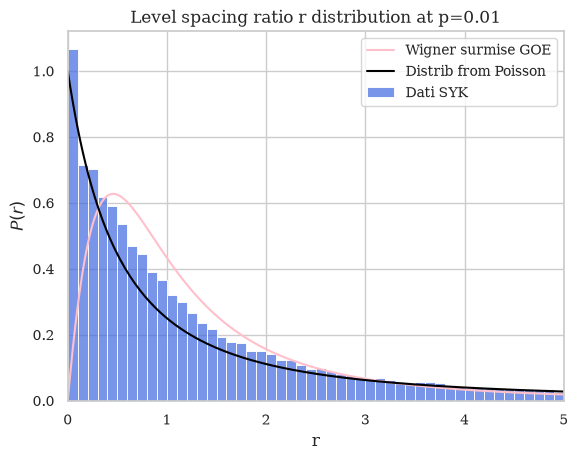

<r> =  56.00509215250722 ± 26.14975821188879


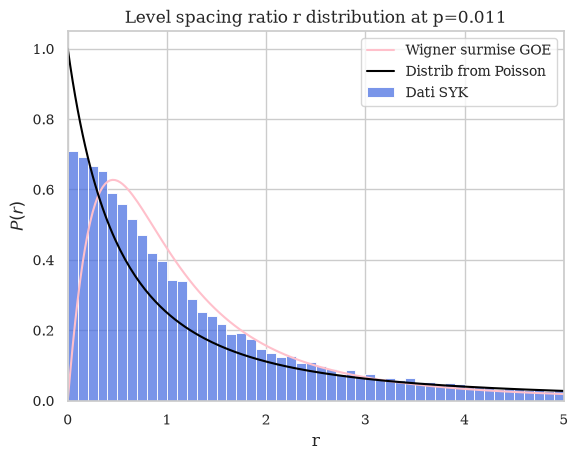

<r> =  20.969841586626682 ± 7.829684598976851


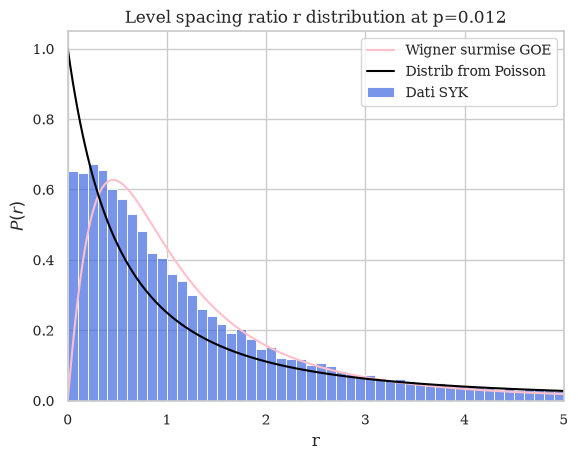

<r> =  6.828394308595303 ± 1.035865770268371


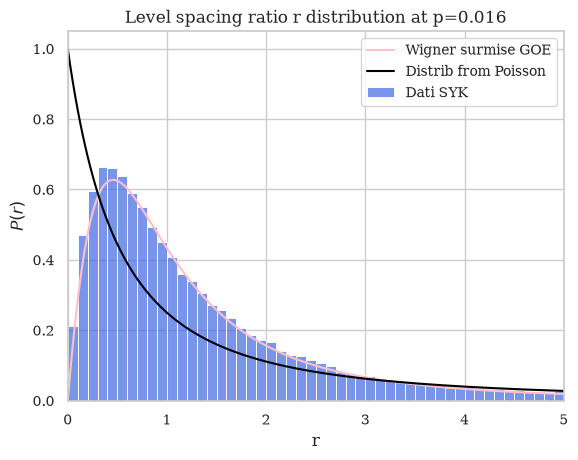

<r> =  1.890383869306405 ± 0.0216686396408905


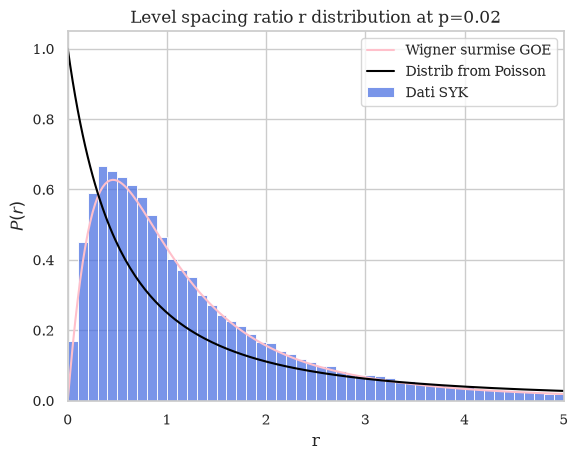

<r> =  1.7878942990279674 ± 0.016498718441283516


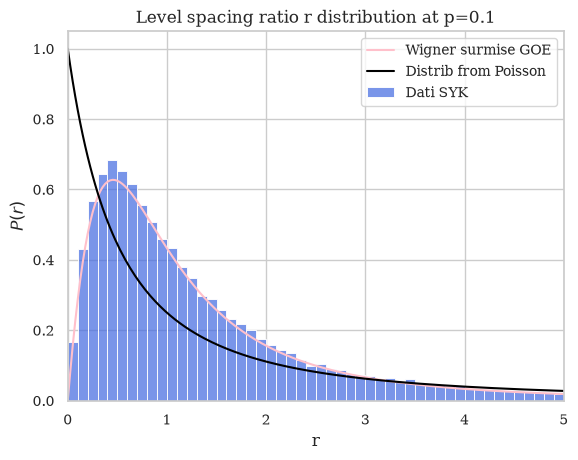

<r> =  1.7791654176112113 ± 0.01573904056917135


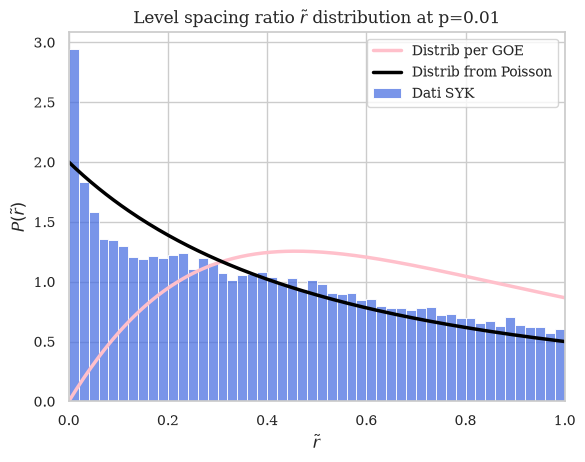

<r_tilde> =  0.4017508559418204 ± 0.006217263030595171


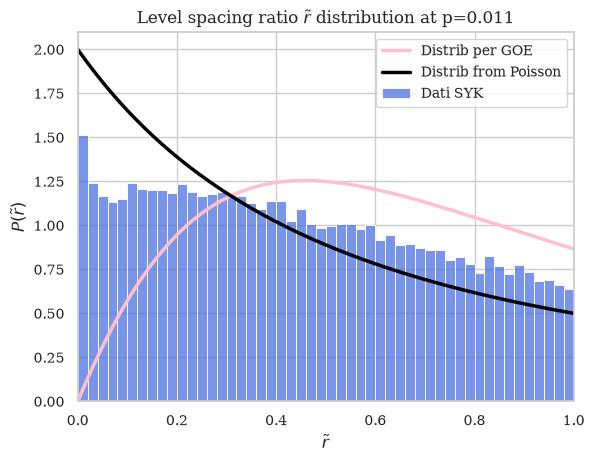

<r_tilde> =  0.4409695871174398 ± 0.005067098181698855


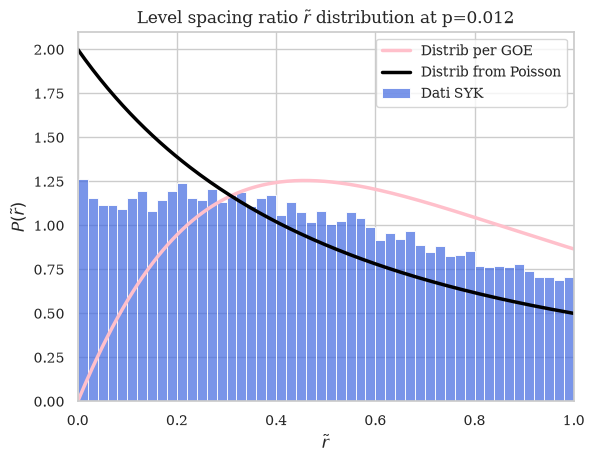

<r_tilde> =  0.45171744447144546 ± 0.005142000407835614


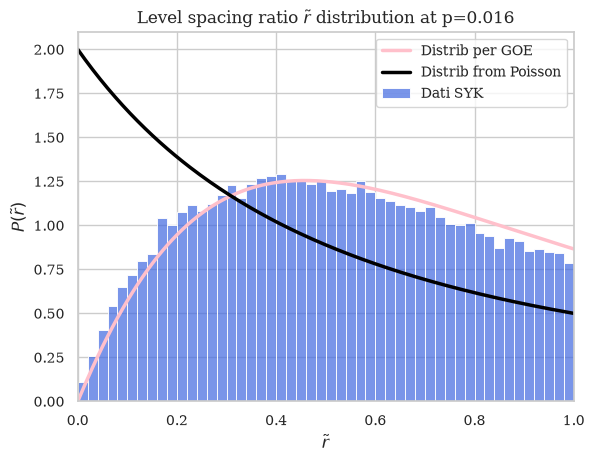

<r_tilde> =  0.5184268473870988 ± 0.0017400483938393308


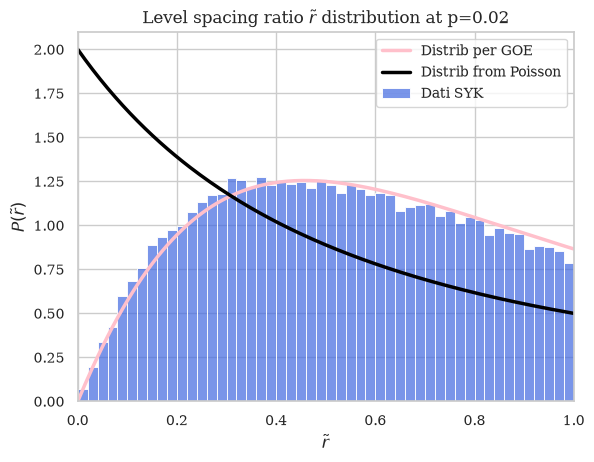

<r_tilde> =  0.5257456020967333 ± 0.0013260967863780472


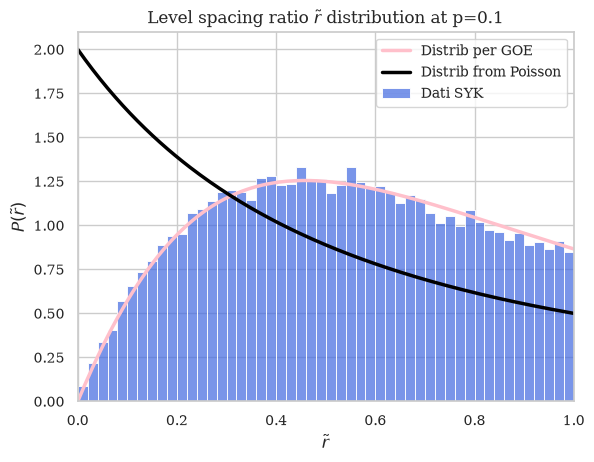

<r_tilde> =  0.5300377456773434 ± 0.0013563879049699416


In [ ]:
N_bin = 50

r_asse = np.linspace(0, 5, 200)
r_index_asse = np.linspace(0, 1, 200)

P_goe = (27/8)*(r_asse + r_asse**2)/(1 + r_asse + r_asse**2)**(2.5)
P_poisson = 1/(1+r_asse)**2

P_index_goe = (27/4)*(r_index_asse + r_index_asse**2)/(1 + r_index_asse + r_index_asse**2)**(2.5)
P_index_poisson = 2/(1+r_index_asse)**2

r_estimate = np.zeros(len(p))
sigma_estimate = np.zeros(len(p))

r_index_estimate = np.zeros(len(p))
sigma_index_estimate = np.zeros(len(p))

for k in range(len(p)):
    sns.histplot(r_list[k], bins=N_bin, binrange=(0,5), stat="density",
             color='royalblue', alpha=0.7, label='SYK Dati')
    plt.plot(r_asse, P_goe, color='pink', linewidth=1.5, label='Wigner surmise GOE')
    plt.plot(r_asse, P_poisson, color='black', linewidth=1.5, label='Distrib from Poisson')
    
    plt.xlabel(r'r')
    plt.ylabel(fr'$P(r)$')
    plt.title(f'Level spacing ratio r distribution at p={p[k]}')
    plt.xlim(0, 5)
    plt.legend()
    plt.show()

    r_estimate[k] = np.mean(r_mean[k])
    sigma_estimate[k] = np.std(r_mean[k])/np.sqrt(len(r_mean[k]))

    

    print(fr"<r> =  {r_estimate[k]} ± {sigma_estimate[k]}")
    
for k in range(len(p)):
    plt.plot(r_index_asse, P_index_goe, color='pink', linewidth=2.5, label='Distrib per GOE')
    plt.plot(r_index_asse, P_index_poisson, color='black', linewidth=2.5, label='Distrib from Poisson')
    sns.histplot(r_index_list[k], bins=N_bin, binrange=(0, 1), stat="density",
                color='royalblue', alpha=0.7, label='SYK data')

    plt.xlabel(fr'$\tilde r$')
    plt.ylabel(fr'$P(\tilde r)$')
    plt.title(fr'Level spacing ratio $\tilde r$ distribution at p={p[k]}')
    plt.xlim(0, 1)
    plt.legend()
    plt.show()

    r_index_estimate[k] = np.mean(r_index_mean[k])
    sigma_index_estimate[k] = np.std(r_index_mean[k])/np.sqrt(len(r_index_mean[k]))

    print(fr"<r_tilde> =  {r_index_estimate[k]} ± {sigma_index_estimate[k]}")

## Cross over

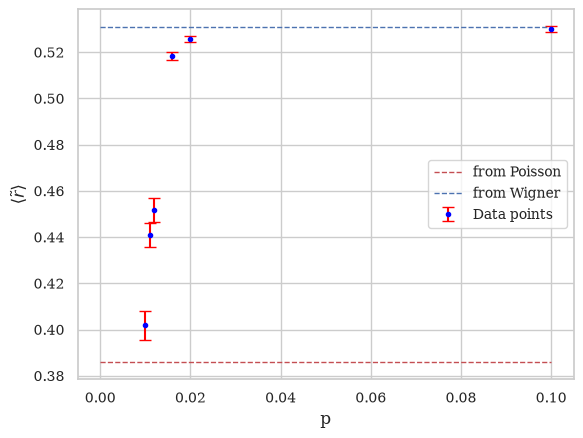

In [9]:

    
plt.errorbar(
    p, r_index_estimate, 
    yerr=sigma_index_estimate,    
    fmt='o',            
    color='blue',       
    markersize=3,
    ecolor='red',      
    capsize=4,           
    label='Data points'
)

m = len(p)
p_asse = np.linspace(0, p[m-1], 200)

poisson = np.zeros(len(p_asse))
poisson = poisson + 0.386

plt.plot(p_asse, poisson, 'r--', linewidth=1, label='from Poisson')

wigner = np.zeros(len(p_asse))
wigner = wigner + 0.531

plt.plot(p_asse, wigner, 'b--', linewidth=1, label='from Wigner')

plt.xlabel(r'p')
plt.ylabel(fr'$\langle \tilde r\rangle$')
plt.xlim()
plt.legend()
plt.show()